**Canvas project group number:** 4  
**Group members:** Abhi Gunasekar, Lily Nguyen, Matthew Surprenant, Parth Harish

# COMPSCI 1090A Final Project — Milestone 2: Data Wrangling and Project Redefinition

**Project:** Propensity vs. Incrementality in Digital Advertising  
**Source:** [Criteo Uplift Prediction Dataset](https://ailab.criteo.com/criteo-uplift-prediction-dataset/)  
**File:** corrected v2.1 release, hosted by [Criteo on Hugging Face](https://huggingface.co/datasets/criteo/criteo-uplift)

This notebook separates acquisition, understanding, cleaning, and the revised question in the order required for Milestone 2.

<div style="background:#E8F1FF;border-left:6px solid #2563EB;padding:14px 18px;border-radius:6px;">
<strong>🎯 Objectives</strong><ul><li>Download or reuse the exact v2.1 source file and report its size.</li><li>Explain the unit of observation, schema, data types, and numerical summaries.</li><li>Audit missingness, unusual values, class balance, scales, and leakage.</li><li>Produce a usable table and a testable project question.</li></ul>
</div>

Full EDA and baseline modeling are Milestone 3 work.

## Part 1. Get the data

Criteo's original release had a documented leakage problem. This notebook uses the corrected **v2.1** release. The file is cached under `data/` and excluded from Git. The download cell does nothing if the verified file is already present. It checks SHA-256 against the value published on the [Criteo Hugging Face file page](https://huggingface.co/datasets/criteo/criteo-uplift/blob/main/criteo-research-uplift-v2.1.csv.gz). Run the notebook from its own directory. Criteo licenses the dataset under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) and asks users to cite Diemert et al., *A Large Scale Benchmark for Uplift Modeling* (AdKDD 2018).

In [1]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

DATA_URL = (
    "https://huggingface.co/datasets/criteo/criteo-uplift/resolve/main/"
    "criteo-research-uplift-v2.1.csv.gz"
)
EXPECTED_SHA256 = "2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc"
DATA_PATH = Path("data/criteo-research-uplift-v2.1.csv.gz")
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)


def sha256_file(path, block_size=8 * 1024 * 1024):
    """Hash a large file without loading it into memory."""
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


if not DATA_PATH.exists():
    temporary_path = DATA_PATH.with_suffix(DATA_PATH.suffix + ".part")
    with urlopen(DATA_URL, timeout=120) as response, temporary_path.open("wb") as output:
        shutil.copyfileobj(response, output, length=8 * 1024 * 1024)
    if sha256_file(temporary_path) != EXPECTED_SHA256:
        temporary_path.unlink()
        raise ValueError("Downloaded file failed the published SHA-256 check")
    temporary_path.replace(DATA_PATH)

actual_hash = sha256_file(DATA_PATH)
if actual_hash != EXPECTED_SHA256:
    raise ValueError(f"Source file hash mismatch: {actual_hash}")

size_mb = DATA_PATH.stat().st_size / 1_000_000
size_gb = DATA_PATH.stat().st_size / 1_000_000_000
print(f"Source file: {DATA_PATH}")
print(f"Compressed size: {size_mb:,.1f} MB ({size_gb:.3f} GB)")
print(f"SHA-256 verified: {actual_hash}")

Source file: data/criteo-research-uplift-v2.1.csv.gz
Compressed size: 311.4 MB (0.311 GB)
SHA-256 verified: 2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc


### Load the complete table

The source is a gzip-compressed CSV. `float32` features and `uint8` binary columns keep the full 14-million-row table practical on a laptop. We use all rows rather than sampling away rare conversions. The source remains untouched.

In [2]:
FEATURES = [f"f{i}" for i in range(12)]
BINARY = ["treatment", "conversion", "visit", "exposure"]
EXPECTED_COLUMNS = FEATURES + BINARY
DTYPES = {**{name: "float32" for name in FEATURES},
          **{name: "uint8" for name in BINARY}}

df = pd.read_csv(DATA_PATH, compression="gzip", dtype=DTYPES)
if list(df.columns) != EXPECTED_COLUMNS:
    raise ValueError(f"Unexpected columns: {list(df.columns)}")

print(f"Loaded table: {len(df):,} rows × {df.shape[1]} columns")
print(f"In-memory size: {df.memory_usage(deep=True).sum() / 1e9:.3f} GB")
display(df.head(3))

Loaded table: 13,979,592 rows × 16 columns
In-memory size: 0.727 GB


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616364,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616364,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616364,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


## Part 2. Understand the data

Criteo describes one row as **one user** in pooled randomized advertising incrementality tests. `treatment=1` means assigned to the ad-eligible group; `treatment=0` means control. Assignment and actual exposure are distinct. Criteo anonymized and projected feature values, so their real-world meanings and natural units are unavailable.

| Column(s) | Meaning | Role in this project |
|---|---|---|
| `f0`–`f11` | Twelve dense, anonymized numerical user/context features | Candidate pre-decision predictors; timing must be confirmed if possible |
| `treatment` | Randomized treatment assignment (1) or control (0) | Design variable for estimating effects |
| `conversion` | Whether the user converted (0/1) | Primary outcome |
| `visit` | Whether the user visited (0/1) | Secondary outcome; not a targeting feature |
| `exposure` | Whether the user was effectively exposed (0/1) | Post-assignment event; not a targeting feature |

The source page's introductory paragraph describes an older 25M-row version. Its **erratum** and the v2.1 file identify the corrected 14M-row version used here.

In [3]:
# Criteo does not release the real-world meaning of any individual f-column.
column_meanings = {
    **{name: "Anonymized dense numerical feature; original meaning unavailable"
       for name in FEATURES},
    "treatment": "Randomized assignment: 1 = treatment, 0 = control",
    "conversion": "Primary binary outcome: whether the user converted",
    "visit": "Secondary binary outcome: whether the user visited",
    "exposure": "Post-assignment binary event: whether an ad was shown",
}
schema = pd.DataFrame({
    "meaning": pd.Series(column_meanings),
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
})
print("Shape:", df.shape)
display(schema)

# All 16 columns are numeric; report the mean, minimum, and maximum of each.
summary = df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(summary.round(4))

Shape: (13979592, 16)


,meaning,dtype,non_null,missing
f0,Anonymized dense numerical feature; original m...,float32,13979592,0
f1,Anonymized dense numerical feature; original m...,float32,13979592,0
f2,Anonymized dense numerical feature; original m...,float32,13979592,0
f3,Anonymized dense numerical feature; original m...,float32,13979592,0
f4,Anonymized dense numerical feature; original m...,float32,13979592,0
f5,Anonymized dense numerical feature; original m...,float32,13979592,0
f6,Anonymized dense numerical feature; original m...,float32,13979592,0
f7,Anonymized dense numerical feature; original m...,float32,13979592,0
f8,Anonymized dense numerical feature; original m...,float32,13979592,0
f9,Anonymized dense numerical feature; original m...,float32,13979592,0


,count,mean,std,min,25%,50%,75%,max
f0,13979592.0,19.6203,5.3775,12.6164,12.6164,21.9234,24.4365,26.7453
f1,13979592.0,10.0700,0.1048,10.0597,10.0597,10.0597,10.0597,16.3442
f2,13979592.0,8.4466,0.2993,8.2144,8.2144,8.2144,8.7233,9.0520
f3,13979592.0,4.1789,1.3366,-8.3984,4.6799,4.6799,4.6799,4.6799
f4,13979592.0,10.3388,0.3433,10.2805,10.2805,10.2805,10.2805,21.1235
f5,13979592.0,4.0285,0.4311,-9.0119,4.1155,4.1155,4.1155,4.1155
f6,13979592.0,-4.1554,4.5779,-31.4298,-6.6993,-2.4111,0.2944,0.2944
f7,13979592.0,5.1018,1.2052,4.8338,4.8338,4.8338,4.8338,11.9984
f8,13979592.0,3.9336,0.0567,3.6351,3.9108,3.9719,3.9719,3.9719
f9,13979592.0,16.0276,7.0190,13.1901,13.1901,13.1901,13.1901,75.2950


## Part 3. Clean and preprocess

The audit below treats anonymized extremes as possible real values, not errors. It checks missingness by treatment arm because deleting rows unevenly could weaken the randomized comparison. It keeps exposure and visit for description but excludes them from any pre-ad targeting feature set.

### 3.1 Missing data and group patterns

In [4]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": 100 * df.isna().mean(),
}).sort_values("missing_count", ascending=False)
display(missing)

# Compare missingness between randomized arms, without fitting a model.
missing_by_arm = pd.concat(
    {arm: 100 * group.isna().mean() for arm, group in df.groupby("treatment")},
    axis=1,
)
missing_by_arm.columns = [f"treatment={arm} (%)" for arm in missing_by_arm.columns]
display(missing_by_arm)

,missing_count,missing_percent
f0,0,0.0
f1,0,0.0
f2,0,0.0
f3,0,0.0
f4,0,0.0
f5,0,0.0
f6,0,0.0
f7,0,0.0
f8,0,0.0
f9,0,0.0


,treatment=0 (%),treatment=1 (%)
f0,0.0,0.0
f1,0.0,0.0
f2,0.0,0.0
f3,0.0,0.0
f4,0.0,0.0
f5,0.0,0.0
f6,0.0,0.0
f7,0.0,0.0
f8,0.0,0.0
f9,0.0,0.0


**Decision rule:** Rows missing treatment or conversion cannot support the primary comparison and would be removed with counts reported. Missing feature values, if any, are retained at this stage; imputation for a future model must be fitted within training folds. Zero missingness requires no imputation.

### 3.2 Unusual values and feature scales

For each feature, inspect the range and 1st/99th percentiles. Those percentiles flag long tails without declaring them erroneous. The features are anonymized, so negative values or outliers are not inherently impossible. Binary fields must contain only 0/1; nonfinite numerical features require investigation.

In [5]:
feature_ranges = pd.DataFrame({
    "min": df[FEATURES].min(),
    "p01": df[FEATURES].quantile(0.01),
    "mean": df[FEATURES].mean(),
    "p99": df[FEATURES].quantile(0.99),
    "max": df[FEATURES].max(),
    "std": df[FEATURES].std(),
})
display(feature_ranges.round(4))

binary_values = {name: sorted(df[name].dropna().unique().tolist()) for name in BINARY}
nonfinite = pd.Series({name: int((~np.isfinite(df[name])).sum()) for name in FEATURES})
print("Observed binary values:", binary_values)
print("Nonfinite feature values:")
display(nonfinite.to_frame("count"))
assert all(set(values) <= {0, 1} for values in binary_values.values())
assert nonfinite.sum() == 0, "Investigate nonfinite feature values before cleaning"

,min,p01,mean,p99,max,std
f0,12.6164,12.6164,19.620300,26.6729,26.745300,5.3775
f1,10.0597,10.0597,10.070000,10.6795,16.344200,0.1048
f2,8.2144,8.2144,8.446600,9.0429,9.052000,0.2993
f3,-8.3984,-1.7332,4.178900,4.6799,4.679900,1.3366
f4,10.2805,10.2805,10.338800,11.9733,21.123501,0.3433
f5,-9.0119,2.2309,4.028500,4.1155,4.115500,0.4311
f6,-31.4298,-17.7773,-4.155400,0.2944,0.294400,4.5779
f7,4.8338,4.8338,5.101800,11.4821,11.998400,1.2052
f8,3.6351,3.7516,3.933600,3.9719,3.971900,0.0567
f9,13.1901,13.1901,16.027599,44.8936,75.294998,7.0190


Observed binary values: {'treatment': [0, 1], 'conversion': [0, 1], 'visit': [0, 1], 'exposure': [0, 1]}
Nonfinite feature values:


,count
f0,0
f1,0
f2,0
f3,0
f4,0
f5,0
f6,0
f7,0
f8,0
f9,0


**Scale decision:** Feature ranges differ. We keep source values for this data audit. For Milestone 3 regularized logistic regression, standardize inside a `Pipeline` after the train/test split, so validation information cannot leak into fitting. Tree-based models generally do not need that scaling.

### 3.3 Class imbalance and treatment design

Count every binary class and conversions within each randomized arm. Accuracy alone will be misleading for a rare outcome. These are descriptive checks, not a fitted model or full EDA.

In [6]:
balance = pd.DataFrame({
    name: df[name].value_counts(dropna=False).reindex([0, 1], fill_value=0)
    for name in BINARY
}).T
balance.columns = ["count_0", "count_1"]
balance["rate_1"] = balance["count_1"] / balance[["count_0", "count_1"]].sum(axis=1)
display(balance)

conversion_by_arm = df.groupby("treatment")["conversion"].agg(
    users="count", conversions="sum", conversion_rate="mean"
)
conversion_by_arm["non_conversions"] = (
    conversion_by_arm["users"] - conversion_by_arm["conversions"]
).astype("int64")
display(conversion_by_arm)

# Assignment does not imply exposure. The cross-tab makes that distinction visible.
display(pd.crosstab(df["treatment"], df["exposure"],
                    rownames=["assigned treatment"], colnames=["actual exposure"]))

# A conversion should normally follow a visit. Check the observed coding.
visit_conversion = pd.crosstab(df["visit"], df["conversion"],
                               rownames=["visit"], colnames=["conversion"])
print("Visit/conversion consistency:")
display(visit_conversion)

,count_0,count_1,rate_1
treatment,2096937,11882655,0.850000
conversion,13938818,40774,0.002917
visit,13322663,656929,0.046992
exposure,13551380,428212,0.030631


,users,conversions,conversion_rate,non_conversions
treatment,,,,
0,2096937,4063,0.001938,2092874
1,11882655,36711,0.003089,11845944


actual exposure,0,1
assigned treatment,,
0,2096937,0
1,11454443,428212


Visit/conversion consistency:


conversion,0,1
visit,,
0,13322663,0
1,616155,40774


### 3.4 Information leakage and cleaned table

A policy must choose whom to target **before** seeing an individual's conversion or visit. `exposure` is realized only after assignment. Therefore `conversion`, `visit`, and `exposure` are never pre-decision predictors. `treatment` is retained for randomized effect estimation, not used as a customer characteristic. The published dataset does not document the measurement time of `f0`–`f11`; we treat them as candidate baseline features and flag that timing as a limitation to discuss with the TF.

We preserve repeated feature profiles: anonymization can map distinct users to identical values, and there is no user ID to prove that two rows are the same person.

In [7]:
# Keep the original rows unless required design fields are missing.
valid_core = df[["treatment", "conversion"]].notna().all(axis=1)
removed_core_rows = int((~valid_core).sum())
cleaned_df = df if removed_core_rows == 0 else df.loc[valid_core].copy()
TARGETING_FEATURES = FEATURES.copy()

print(f"Rows removed for missing treatment/conversion: {removed_core_rows:,}")
print(f"Cleaned table: {cleaned_df.shape[0]:,} rows × {cleaned_df.shape[1]} columns")
print(f"Pre-decision candidate features ({len(TARGETING_FEATURES)}): {TARGETING_FEATURES}")
assert set(TARGETING_FEATURES).isdisjoint({"treatment", "conversion", "visit", "exposure"})
assert len(cleaned_df) > 0

Rows removed for missing treatment/conversion: 0
Cleaned table: 13,979,592 rows × 16 columns
Pre-decision candidate features (12): ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']


### Reproducible analysis sample for later milestones

The [approved-project list](https://docs.google.com/spreadsheets/d/1HY5RJGxsq3D0Hq899r35iu7vO4Sutir15zAuvxndMnc/edit) marks this project **Approved** and advises a random sample that runs comfortably on a laptop while retaining enough conversions. The full table above is kept for the Milestone 2 audit. The code below draws a simple random sample without replacement for later modeling; it does **not** stratify on conversion or treatment, so it preserves their natural proportions. We report the realized counts rather than assuming they are adequate for every subgroup or model.

In [8]:
SAMPLE_SIZE = 5_000_000
analysis_df = cleaned_df.sample(n=min(SAMPLE_SIZE, len(cleaned_df)),
                                random_state=109).copy()

sample_counts = analysis_df.groupby("treatment")["conversion"].agg(
    users="count", conversions="sum", conversion_rate="mean"
)
print(f"Seeded analysis sample: {len(analysis_df):,} rows × {analysis_df.shape[1]} columns")
print(f"Sample memory: {analysis_df.memory_usage(deep=True).sum() / 1e9:.3f} GB")
display(sample_counts)
assert set(sample_counts.index) == {0, 1}
assert sample_counts["conversions"].min() > 0

Seeded analysis sample: 5,000,000 rows × 16 columns
Sample memory: 0.300 GB


,users,conversions,conversion_rate
treatment,,,
0,750806,1442,0.001921
1,4249194,13052,0.003072


### Observed cleaning results

Running the notebook on the verified v2.1 file produced **13,979,592 rows and 16 columns**. All 16 columns have **zero missing values**; the 12 feature columns have **zero nonfinite values**; all four binary columns contain only 0 and 1. No row was removed. The cleaned table therefore retains the complete randomized sample.

The treatment arm has **11,882,655 users** and the control arm **2,096,937**. There are **40,774 conversions total** (about **0.292%**): 36,711 in treatment and 4,063 in control. This severe imbalance makes accuracy a poor standalone metric. The anonymized features differ substantially in range (for example, `f6` spans roughly -31.43 to 0.29 while `f8` spans 3.64 to 3.97); standardized linear models should scale within their training pipelines. These ranges cannot be labeled impossible without feature definitions, so no values are trimmed.

The seeded 5,000,000-row analysis sample contains **13,052 treatment conversions** and **1,442 control conversions**; its table occupies about **0.300 GB** in memory. This sample is for model development, not a substitute for the full-table Milestone 2 audit.

Only **428,212 treated users** have recorded exposure, and controls have none. Exposure is distinct from randomized assignment; conditioning on it would change the comparison. Conversion, visit, and exposure remain in the table for analysis but are excluded from targeting predictors.

The visit/conversion cross-tab confirms that **all 40,774 conversions also have a recorded visit**. Visits are more common (656,929) and remain a distinct secondary outcome. No inconsistent visit/conversion rows needed removal.

## Part 4. Data-focused plots

These two plots verify missingness and class balance. Full feature exploration and modeling come next milestone.

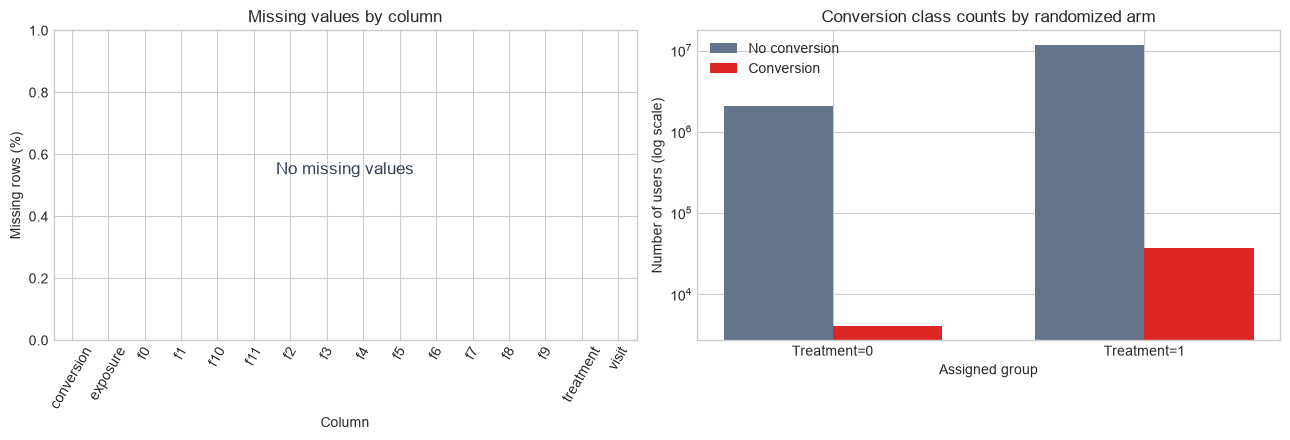

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

missing.sort_index()["missing_percent"].plot.bar(ax=axes[0], color="#2563EB")
axes[0].set(title="Missing values by column", xlabel="Column", ylabel="Missing rows (%)")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylim(0, 1)
if missing["missing_count"].sum() == 0:
    axes[0].text(0.5, 0.55, "No missing values", transform=axes[0].transAxes,
                 ha="center", va="center", fontsize=12, color="#334155")

x = np.arange(len(conversion_by_arm))
width = 0.35
axes[1].bar(x - width / 2, conversion_by_arm["non_conversions"], width,
            label="No conversion", color="#64748B")
axes[1].bar(x + width / 2, conversion_by_arm["conversions"], width,
            label="Conversion", color="#DC2626")
axes[1].set(xticks=x, xticklabels=[f"Treatment={arm}" for arm in conversion_by_arm.index],
            title="Conversion class counts by randomized arm", xlabel="Assigned group",
            ylabel="Number of users (log scale)", yscale="log")
axes[1].legend()
fig.tight_layout()
plt.show()

## Part 5. Revised project question

**Testable question:** At a fixed audience fraction, does ranking users by estimated incremental conversion response yield more incremental conversions than ranking them by predicted conversion probability without advertising, when both policies are evaluated on held-out randomized treatment/control data?

The approved proposal already posed this comparison. The corrected v2.1 data provide a large randomized treatment/control table and a rare conversion outcome, so the question remains answerable in principle. The working Milestone 3 plan is to estimate no-ad conversion propensity from controls with regularized logistic regression and compare tree-based models; estimate uplift with separate treatment and control response models; and evaluate the rankings on held-out randomized data at equal audience fractions. Propensity models will also be checked with rare-event metrics such as precision-recall performance, probability calibration, and log loss. The group will select final models and a policy-value estimator with uncertainty intervals before fitting. Any comparison must account for the unequal treatment allocation and must not use realized exposure or visits to rank users.

**Limitation:** The dataset is non-uniformly subsampled for privacy, so its raw treatment-control difference should not be interpreted as the original advertisers' population-wide incremental return. The anonymized features also limit customer-level interpretation. Confirm the intended estimand and feature timing with the TF.

<div style="background:#F3E8FF;border-left:6px solid #7E22CE;padding:14px 18px;border-radius:6px;">
<strong>🧠 Key data takeaways for the slides and revised proposal</strong>
<ol>
<li><strong>Source and unit:</strong> Criteo's corrected v2.1 randomized advertising dataset; one row is one user. The verified gzip file is 311.4 MB and the loaded table occupies about 0.727 GB.</li>
<li><strong>Usable table:</strong> 13,979,592 rows × 16 columns after cleaning. There are 12 anonymized numerical features, randomized assignment, exposure, visit, and conversion. No rows were removed.</li>
<li><strong>Quality decisions:</strong> Every column has zero missing values; features have no nonfinite values; binary fields contain only 0/1. Large or negative anonymized feature values cannot be judged impossible, so none were trimmed. Feature ranges differ and future linear models will scale within training pipelines.</li>
<li><strong>Rare outcome and design:</strong> 40,774 conversions (0.292%): 36,711 among 11,882,655 treated users and 4,063 among 2,096,937 controls. Accuracy alone is inadequate. Assignment and actual exposure differ; only 428,212 users have recorded exposure. All 40,774 converters also have a recorded visit, but 656,929 users visited overall.</li>
<li><strong>Leakage boundary:</strong> Candidate targeting inputs are `f0`–`f11`. `conversion`, `visit`, and `exposure` occur after the decision; `treatment` is used to estimate effects, not to rank users. The timing of anonymized features remains a source limitation to raise with the TF.</li>
<li><strong>Feasible next step:</strong> The project is marked Approved; staff advises a laptop-sized random sample. A seeded 5,000,000-user random sample occupies about 0.300 GB and retains 14,494 conversions (1,442 control; 13,052 treatment). The slides and proposal should explain this sample, the rare-event constraint, and why the source privacy subsampling limits population-wide claims.</li>
<li><strong>Question retained and sharpened:</strong> At a fixed audience fraction, does estimated incremental-response targeting produce more incremental conversions than baseline-propensity targeting on held-out randomized data? The working plan is control-group propensity models (regularized logistic regression and tree-based alternatives), separate treatment/control response models for uplift, and held-out policy-value comparisons at equal audience fractions with uncertainty. Rare-event precision-recall and probability quality will complement, not replace, the incremental-conversion decision metric.</li>
</ol>
</div>